# 05 · Prediction – does COG allocation predict growth rate in an unseen study?

**Why.** An association found inside the pooled data is convincing only if it transfers. The intended use is "a new laboratory measures a proteome", so the split holds out an entire **dataset**, never random rows.

**Model.** Partial least squares regression of growth rate on the COG mass fractions (collinear, compositional predictors; few conditions). Scaling and PLS form one scikit-learn `Pipeline`.

**Where leakage could enter, and how it is closed**

| risk | control |
|---|---|
| scaling learned on all conditions | scaler is inside the pipeline, fitted on training folds only |
| replicates or one study on both sides of a split | replicates averaged; leave-one-dataset-out |
| tuning on the evaluation data | nested: inner leave-one-dataset-out chooses the number of components from outer-training data only |
| features built with held-out information | fractions are computed within each sample; annotation is external |
| reporting the best of several runs | every trial is saved; one pre-specified grid; one seed |

The score is reported next to a mean-predictor baseline and a permutation null (growth rates shuffled within dataset, the whole nested procedure repeated, in parallel).

In [1]:
import sys
from pathlib import Path

# repository root = first parent folder that contains config.yml (no machine-specific paths)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yml").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from proteome_alloc import config, ingest, annotation, scope, allocation, asca, predict, plots, combined, proteomap
from proteome_alloc.ingest import GROWTH

cfg = config.load_config()
pd.set_option("display.max_columns", 40, "display.width", 220, "display.max_colwidth", 60)
print("Repository root :", cfg.root)
print("Config file     :", cfg.config_file.name, "| master seed:", cfg["seed"])

Repository root : C:\Users\arlin\OneDrive\Documentos\proteome_allocation\proteome_allocation
Config file     : config.yml | master seed: 20261011


In [2]:
Fc = pd.read_csv(cfg.tables / "03_cog_fractions_per_condition.tsv", sep="\t", index_col=0)
info = pd.read_csv(cfg.tables / "03_condition_table.tsv", sep="\t", index_col=0)
labels = annotation.category_labels(cfg)
print("Conditions x COG categories:", Fc.shape)
display(info.groupby("Dataset_Source").agg(n_conditions=(GROWTH, "size"), growth_min=(GROWTH, "min"), growth_max=(GROWTH, "max")))

Conditions x COG categories: (28, 27)


,n_conditions,growth_min,growth_max
Dataset_Source,,,
mori_2021,7,0.48928,1.124022
schmidt_2016,2,1.03000,2.300000
wu_2023,13,0.67000,2.190000
zhu_2025,6,0.42000,1.900000


In [3]:
result = predict.evaluate(Fc, info, cfg)

print("Features used:", ", ".join(result["features"]))
display(result["folds"].round(3))
print(f"Pooled RMSE  model {result['rmse_model']:.3f} h-1 | mean baseline {result['rmse_baseline']:.3f} h-1")
print(f"Pooled MAE   model {result['mae_model']:.3f} h-1")
print(f"Q2 relative to the baseline: {result['q2_vs_baseline']:.3f}")
print(f"Permutation p (n = {len(result['null_rmse'])}): {result['p_permutation']:.4f}")
print(f"Configurations evaluated in total: {result['n_configurations_tried']}")

Features used: J, A, K, L, D, V, T, M, N, Z, W, U, O, X, C, G, E, F, H, I, P, Q, R, S


,held_out_dataset,n_train,n_test,n_components,rmse_model,rmse_baseline
0,mori_2021,21,7,1,0.355,0.515
1,schmidt_2016,26,2,2,0.558,0.854
2,wu_2023,15,13,2,0.139,0.498
3,zhu_2025,22,6,3,0.567,0.488


Pooled RMSE  model 0.363 h-1 | mean baseline 0.534 h-1
Pooled MAE   model 0.273 h-1
Q2 relative to the baseline: 0.538
Permutation p (n = 200): 0.0050
Configurations evaluated in total: 15


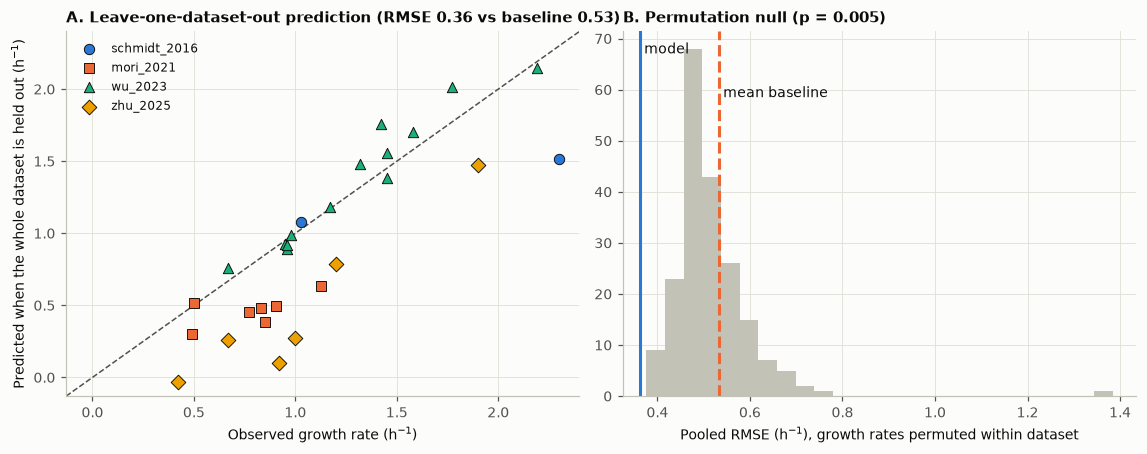

In [4]:
fig = plots.plot_prediction(result, cfg.figures / "05_prediction_leave_one_dataset_out.png")
plt.show()

Observed-versus-predicted is shown because the claim is about agreement of individual predictions; the dashed line is perfect agreement and marker shape identifies the held-out dataset. Panel B places the observed error in the distribution obtained when growth rates carry no information.

## 1 · Every tuning trial

The table lists each candidate number of components, its inner cross-validation error and which one was selected, for every outer fold. Selected settings alone would not show how the model was chosen.

In [5]:
display(result["trials"].round(4))

,n_components,feasible,inner_rmse,outer_fold_held_out,selected
0,1,True,0.3286,mori_2021,True
1,2,True,0.4281,mori_2021,False
2,3,True,0.7062,mori_2021,False
3,1,True,0.1783,schmidt_2016,False
4,2,True,0.1370,schmidt_2016,True
5,3,True,0.2287,schmidt_2016,False
6,1,True,0.4923,wu_2023,False
7,2,True,0.4571,wu_2023,True
8,3,True,0.5013,wu_2023,False
9,1,True,0.6471,zhu_2025,False


## 2 · Final model and coefficient stability (jackknife over datasets)

After evaluation, the same selection procedure is run on all conditions to fix the final model. Its coefficients are then recomputed leaving each dataset out; the jackknife standard error and the sign stability show which categories drive the prediction consistently.

In [6]:
coefficients = result["coefficients"].assign(description=labels.reindex(result["coefficients"].index))
print("Final number of PLS components:", result["final_n_components"])
display(coefficients.sort_values("coefficient_h-1_per_unit_fraction").round(3))

Final number of PLS components: 1


,coefficient_h-1_per_unit_fraction,jackknife_se,sign_stable,coef_without_mori_2021,coef_without_schmidt_2016,coef_without_wu_2023,coef_without_zhu_2025,description
COG_Category,,,,,,,,
W,-2670.729,6595.987,False,-7388.711,-1593.202,3210.441,-2642.234,Extracellular structures
X,-68.592,299.075,True,-413.534,-54.497,-60.998,-73.118,"Mobilome: prophages, transposons"
S,-39.086,31.617,True,-74.466,-30.401,-37.964,-41.184,Function unknown
Q,-8.460,14.220,True,-8.873,-6.392,-5.980,-24.554,"Secondary metabolites biosynthesis, transport and catabo..."
R,-8.181,12.424,True,-8.448,-3.494,-5.871,-21.540,General function prediction only
H,-6.871,1.611,True,-6.045,-5.486,-6.637,-7.768,Coenzyme transport and metabolism
T,-6.648,1.685,True,-5.731,-5.543,-7.514,-7.634,Signal transduction mechanisms
N,-5.122,1.346,True,-5.951,-4.845,-4.087,-4.361,Cell motility
I,-4.156,1.853,True,-3.786,-3.350,-5.778,-3.079,Lipid transport and metabolism


## 3 · What this result can and cannot support

* Each outer fold is one study, so there are as many independent evaluations as datasets. A fold with very few conditions gives a noisy error estimate; read the per-fold table, not only the pooled number.
* The permutation p-value cannot be smaller than `1 / (n_permutations + 1)`.
* This is internal validation across four studies of one strain background. It does not show that the model transfers to other strains or to non-nutrient perturbations, which were excluded by design.
* PLS coefficients of compositional predictors are not causal effects; use notebook 03 for effect sizes.

In [7]:
outputs = [cfg.tables / "05_predictions.tsv", cfg.tables / "05_outer_folds.tsv", cfg.tables / "05_tuning_trials.tsv",
           cfg.tables / "05_pls_coefficients.tsv", cfg.tables / "05_split_membership.tsv"]
result["predictions"].to_csv(outputs[0], sep="\t"); result["folds"].to_csv(outputs[1], sep="\t", index=False)
result["trials"].to_csv(outputs[2], sep="\t", index=False); coefficients.to_csv(outputs[3], sep="\t")
result["predictions"][["outer_fold"]].rename(columns={"outer_fold": "held_out_with_dataset"}).to_csv(outputs[4], sep="\t")

config.log_run(cfg, "05_prediction_validation", params={"prediction": cfg["prediction"]}, outputs=outputs,
               notes={"rmse_model": result["rmse_model"], "rmse_baseline": result["rmse_baseline"],
                      "mae_model": result["mae_model"], "q2_vs_baseline": result["q2_vs_baseline"],
                      "p_permutation": result["p_permutation"], "final_n_components": result["final_n_components"],
                      "n_configurations_tried": result["n_configurations_tried"], "features": result["features"]})
print("Tables written to", cfg.tables.relative_to(cfg.root))

Tables written to results\tables
